# Superhero Intelligence System
## Can Six Ability Scores Tell a Hero from a Villain?
**Machine Learning Assignment Report & Executable Notebook**

---

### Project Overview & Architecture
This project investigates whether six core ability scores (*intelligence, strength, speed, durability, power, combat*) can distinguish superheroes from supervillains and uncover natural unsupervised archetypes.

The investigation is structured into five core sections:
1. **Section 1: Setup & Data Verification** &mdash; Loading the Hugging Face Superheroes dataset and establishing reproducible environments.
2. **Section 2: Data Preparation (10 Marks)** &mdash; Applying standardized inspection, deduplication, missing value encoding, weak row pruning, and pipeline-based imputation to create **Clean Set A** and **Clean Set B**.
3. **Section 3: Task 1 &middot; Supervised Classification (25 Marks)** &mdash; Establishing a dummy baseline and optimizing Decision Tree and K-Nearest Neighbors (KNN) models via 5-fold Stratified Cross-Validation using Macro-F1.
4. **Section 4: Task 2 &middot; Unsupervised Clustering (25 Marks)** &mdash; Discovering character archetypes on unlabelled data using K-Means and Agglomerative Hierarchical Clustering, validated with Silhouette, Davies-Bouldin, Calinski-Harabasz, and Adjusted Rand Index (ARI).
5. **Section 5: Task 3 &middot; Feed-Forward Neural Networks (25 Marks)** &mdash; Implementing, regularizing (early stopping), and evaluating shallow and deep Multi-Layer Perceptrons (Network A and Network B).
6. **Section 6: Synthesis & Final Evaluation** &mdash; Unlocking the final unseen test set to establish an overarching model ranking (Table T11) and addressing research questions Q1&ndash;Q12.


In [1]:
# Global Configuration, Seeds, and Style Specifications
import os
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, f1_score,
    confusion_matrix, classification_report, log_loss
)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA

# SciPy
from scipy.cluster.hierarchy import linkage, dendrogram

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

# Set global seeds for strict reproducibility
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Fixed Colour Palette (Strict specification from project brief)
PALETTE = {
    'Hero': '#1F5FBF',        # Good / Hero
    'Villain': '#D62839',     # Bad / Villain
    'Baseline': '#9E9E9E',    # Baseline Dummy
    'Decision Tree': '#2E7D32',# Decision Tree
    'KNN': '#F9A825',          # KNN
    'Network A': '#6A1B9A',   # Neural Network A
    'Network B': '#00838F'    # Neural Network B
}

# The 6 mandatory input feature columns
SCORE_COLS = [
    'intelligence_score',
    'strength_score',
    'speed_score',
    'durability_score',
    'power_score',
    'combat_score'
]

print("✓ All libraries imported and global configuration initialized.")


✓ All libraries imported and global configuration initialized.


## Section 2: Data Preparation (10 Marks)

### Cleaning Protocol & Rules:
The preparation protocol strictly applies Steps 1–4 to both `train.csv` and `test.csv` in identical sequence:
1. **Step 1: Inspect** &mdash; Characterize row/column dimensions, verify schema, and count raw zeros/blanks across ability attributes.
2. **Step 2: Remove Duplicates** &mdash; For duplicates within a file, retain the first occurrence. For names appearing in both `train.csv` and `test.csv`, remove them from `train.csv`. Characters with distinguishing suffixes (e.g. *"Captain X"* vs. *"Captain X (Film)"*) represent distinct character iterations and are preserved.
3. **Step 3: Mark Missing** &mdash; Cast the six scores to numeric and translate `0` and empty strings to `NaN` (in superhero databases, a zero score denotes unrecorded/unknown attributes rather than complete absence of physical ability).
4. **Step 4: Remove Weak Rows** &mdash; Prune any character record lacking $\ge 3$ of the six ability metrics.
5. **Clean Sets Branching**:
   - **Clean Set A (for Task 2 Clustering)**: Derived solely from `train.csv`. Includes all characters (Good, Bad, Neutral, blank). The `alignment` label is sequestered and never exposed to the clustering models.
   - **Clean Set B (for Tasks 1 & 3 Supervised Learning)**: Filtered strictly to characters with confirmed `alignment` $\in \{\text{'Good'}, \text{'Bad'}\}$. Mapped as **Good $\rightarrow$ 0 (Hero)**, **Bad $\rightarrow$ 1 (Villain)**.
6. **Step 5: Imputation** &mdash; Remaining missing values ($< 3$ missing per row) are imputed using the **training median** within automated scikit-learn pipelines. Test sets remain unseen.


In [2]:
# Execute Data Cleaning Protocol (Steps 1 - 4)

# Load original raw data
train_raw = pd.read_csv("data/train.csv")
test_raw = pd.read_csv("data/test.csv")

loaded_train_n = len(train_raw)
loaded_test_n = len(test_raw)

# Step 1: Count zeros and blanks that become NaN
t1_records = []
for col in SCORE_COLS:
    tr_blanks = train_raw[col].isna().sum()
    tr_zeros = (train_raw[col] == 0).sum()
    te_blanks = test_raw[col].isna().sum()
    te_zeros = (test_raw[col] == 0).sum()
    t1_records.append({
        'Feature': col,
        'Train Blanks': tr_blanks,
        'Train Zeros': tr_zeros,
        'Train Total -> NaN': tr_blanks + tr_zeros,
        'Test Blanks': te_blanks,
        'Test Zeros': te_zeros,
        'Test Total -> NaN': te_blanks + te_zeros
    })
table_t1 = pd.DataFrame(t1_records)

# Step 2: Remove Duplicates
train_dedup = train_raw.drop_duplicates(subset=['name'], keep='first').copy()
test_dedup = test_raw.drop_duplicates(subset=['name'], keep='first').copy()

test_names = set(test_dedup['name'])
train_step2 = train_dedup[~train_dedup['name'].isin(test_names)].copy()
test_step2 = test_dedup.copy()

step2_train_n = len(train_step2)
step2_test_n = len(test_step2)

# Step 3: Mark Missing (0 and blank -> NaN)
for df in [train_step2, test_step2]:
    for col in SCORE_COLS:
        df[col] = pd.to_numeric(df[col], errors='coerce').replace(0, np.nan)
    df['missing_count'] = df[SCORE_COLS].isna().sum(axis=1)

# Step 4: Remove Weak Rows (drop if missing >= 3)
train_step4 = train_step2[train_step2['missing_count'] < 3].copy()
test_step4 = test_step2[test_step2['missing_count'] < 3].copy()

step4_train_n = len(train_step4)
step4_test_n = len(test_step4)

# Create Clean Set A (Task 2: train only, all characters)
clean_set_a = train_step4.copy()
set_a_train_n = len(clean_set_a)

# Create Clean Set B (Tasks 1 & 3: train & test, Good & Bad only)
train_neutral_blank_count = len(train_step4) - train_step4['alignment'].isin(['Good', 'Bad']).sum()
test_neutral_blank_count = len(test_step4) - test_step4['alignment'].isin(['Good', 'Bad']).sum()

clean_set_b_train = train_step4[train_step4['alignment'].isin(['Good', 'Bad'])].copy()
clean_set_b_test = test_step4[test_step4['alignment'].isin(['Good', 'Bad'])].copy()

# Target encoding: Good -> 0 (Hero), Bad -> 1 (Villain)
alignment_mapping = {'Good': 0, 'Bad': 1}
clean_set_b_train['target'] = clean_set_b_train['alignment'].map(alignment_mapping)
clean_set_b_test['target'] = clean_set_b_test['alignment'].map(alignment_mapping)

set_b_train_n = len(clean_set_b_train)
set_b_test_n = len(clean_set_b_test)

# Build Table T2: Rows after each step
table_t2 = pd.DataFrame([
    {'Step': 'Loaded', 'train.csv': loaded_train_n, 'test.csv': loaded_test_n},
    {'Step': 'After step 2 (duplicates)', 'train.csv': step2_train_n, 'test.csv': step2_test_n},
    {'Step': 'After step 4 (weak rows)', 'train.csv': step4_train_n, 'test.csv': step4_test_n},
    {'Step': 'Clean Set A', 'train.csv': set_a_train_n, 'test.csv': 'not used'},
    {'Step': 'Clean Set B', 'train.csv': set_b_train_n, 'test.csv': set_b_test_n}
])

print("=== Table T1: Missing Values and 0s Converted to NaN ===")
print(table_t1.to_string(index=False))

print("\n=== Table T2: Character Row Counts After Each Cleaning Step ===")
print(table_t2.to_string(index=False))

print(f"\nFiltered Neutral & Blank alignments in Step 4 -> Clean Set B:")
print(f"  • train.csv: {train_neutral_blank_count} rows removed")
print(f"  • test.csv:  {test_neutral_blank_count} rows removed")


=== Table T1: Missing Values and 0s Converted to NaN ===
           Feature  Train Blanks  Train Zeros  Train Total -> NaN  Test Blanks  Test Zeros  Test Total -> NaN
intelligence_score             0           85                  85            0          20                 20
    strength_score             0           91                  91            0          22                 22
       speed_score             0           86                  86            0          20                 20
  durability_score             0           87                  87            0          20                 20
       power_score             0           57                  57            0          14                 14
      combat_score             0           85                  85            0          20                 20

=== Table T2: Character Row Counts After Each Cleaning Step ===
                     Step  train.csv test.csv
                   Loaded       1158      290
After step 2 (du

## Section 3: Task 1 &middot; Supervised Classification (25 Marks)

### Objective & Methodology
Task 1 evaluates whether the six quantitative ability scores allow machine learning classifiers to determine whether a character is a **Hero (0)** or a **Villain (1)**.
* **Dataset:** Clean Set B (`train.csv` exclusively for model fitting and hyperparameter selection; `test.csv` held locked until final scoring).
* **Models Tested:**
  1. **Baseline**: `DummyClassifier(strategy="most_frequent")`.
  2. **Decision Tree**: `SimpleImputer(strategy="median")` $\rightarrow$ `DecisionTreeClassifier(criterion="gini", random_state=42)`.
     - Hyperparameter Grid: `max_depth` $\in [3, 5, 7, 10, \text{None}]$, `min_samples_leaf` $\in [1, 5, 10]$ (15 combinations).
  3. **K-Nearest Neighbours (KNN)**: `SimpleImputer(strategy="median")` $\rightarrow$ `StandardScaler()` $\rightarrow$ `KNeighborsClassifier(metric="euclidean")`.
     - Hyperparameter Grid: `n_neighbors` $\in [3, 5, 7, 9, 11, 15]$, `weights` $\in [\text{"uniform"}, \text{"distance"}]$ (12 combinations).
* **Cross-Validation Scheme:** 5-fold Stratified K-Fold (`shuffle=True, random_state=42`) using **Macro-F1** as the optimization criterion (`refit=True`).
* **Evaluation Metrics:** Accuracy, Precision, Recall, F1 for each class, and unweighted Macro-F1.


In [3]:
# Task 1: Training, Grid Search, and Results Compilation

X_train_b = clean_set_b_train[SCORE_COLS]
y_train_b = clean_set_b_train['target']
X_test_b = clean_set_b_test[SCORE_COLS]
y_test_b = clean_set_b_test['target']

# Table T3: Class counts and percentages in each file
train_good = int((y_train_b == 0).sum())
train_bad = int((y_train_b == 1).sum())
test_good = int((y_test_b == 0).sum())
test_bad = int((y_test_b == 1).sum())

table_t3 = pd.DataFrame([
    {
        'Split': 'train.csv',
        'Hero (0)': train_good,
        'Hero %': f"{(train_good / len(y_train_b)) * 100:.2f}%",
        'Villain (1)': train_bad,
        'Villain %': f"{(train_bad / len(y_train_b)) * 100:.2f}%",
        'Total': len(y_train_b)
    },
    {
        'Split': 'test.csv',
        'Hero (0)': test_good,
        'Hero %': f"{(test_good / len(y_test_b)) * 100:.2f}%",
        'Villain (1)': test_bad,
        'Villain %': f"{(test_bad / len(y_test_b)) * 100:.2f}%",
        'Total': len(y_test_b)
    }
])

# 1. Baseline Model
baseline_clf = DummyClassifier(strategy="most_frequent")
baseline_clf.fit(X_train_b, y_train_b)

# 2. Decision Tree Pipeline & GridSearchCV
dt_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeClassifier(criterion='gini', random_state=SEED))
])
dt_param_grid = {
    'model__max_depth': [3, 5, 7, 10, None],
    'model__min_samples_leaf': [1, 5, 10]
}
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
dt_grid = GridSearchCV(dt_pipe, dt_param_grid, cv=cv_strat, scoring='f1_macro', refit=True)
dt_grid.fit(X_train_b, y_train_b)

# 3. KNN Pipeline & GridSearchCV
knn_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(metric='euclidean'))
])
knn_param_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15],
    'model__weights': ['uniform', 'distance']
}
knn_grid = GridSearchCV(knn_pipe, knn_param_grid, cv=cv_strat, scoring='f1_macro', refit=True)
knn_grid.fit(X_train_b, y_train_b)

# Table T4: Best settings and best CV macro-F1
table_t4 = pd.DataFrame([
    {
        'Model': 'Decision Tree',
        'Best Hyperparameters': f"max_depth={dt_grid.best_params_['model__max_depth']}, min_samples_leaf={dt_grid.best_params_['model__min_samples_leaf']}",
        'Best CV Macro-F1': round(dt_grid.best_score_, 4)
    },
    {
        'Model': 'KNN',
        'Best Hyperparameters': f"n_neighbors={knn_grid.best_params_['model__n_neighbors']}, weights='{knn_grid.best_params_['model__weights']}'",
        'Best CV Macro-F1': round(knn_grid.best_score_, 4)
    }
])

# Model Evaluation on Train and Unlocked Test
models = {
    'Baseline': baseline_clf,
    'Decision Tree': dt_grid.best_estimator_,
    'KNN': knn_grid.best_estimator_
}

t5_rows = []
predictions_dict = {}

for name, model in models.items():
    y_tr_pred = model.predict(X_train_b)
    y_te_pred = model.predict(X_test_b)
    predictions_dict[name] = y_te_pred
    
    tr_macro_f1 = f1_score(y_train_b, y_tr_pred, average='macro')
    te_acc = accuracy_score(y_test_b, y_te_pred)
    p_hero, r_hero, f1_hero, _ = precision_recall_fscore_support(y_test_b, y_te_pred, labels=[0], average=None, zero_division=0)
    p_villain, r_villain, f1_villain, _ = precision_recall_fscore_support(y_test_b, y_te_pred, labels=[1], average=None, zero_division=0)
    te_macro_f1 = f1_score(y_test_b, y_te_pred, average='macro')
    
    t5_rows.append({
        'Model': name,
        'Train Macro-F1': round(tr_macro_f1, 4),
        'Accuracy': round(te_acc, 4),
        'Precision Hero': round(p_hero[0], 4),
        'Recall Hero': round(r_hero[0], 4),
        'F1 Hero': round(f1_hero[0], 4),
        'Precision Villain': round(p_villain[0], 4),
        'Recall Villain': round(r_villain[0], 4),
        'F1 Villain': round(f1_villain[0], 4),
        'Macro-F1': round(te_macro_f1, 4)
    })

table_t5 = pd.DataFrame(t5_rows)

print("=== Table T3: Class Distribution in Clean Set B ===")
print(table_t3.to_string(index=False))

print("\n=== Table T4: Optimal Hyperparameters from 5-Fold Cross Validation ===")
print(table_t4.to_string(index=False))

print("\n=== Table T5: Task 1 Comprehensive Classification Results ===")
print(table_t5.to_string(index=False))


=== Table T3: Class Distribution in Clean Set B ===
    Split  Hero (0) Hero %  Villain (1) Villain %  Total
train.csv       588 64.19%          328    35.81%    916
 test.csv       137 60.89%           88    39.11%    225

=== Table T4: Optimal Hyperparameters from 5-Fold Cross Validation ===
        Model             Best Hyperparameters  Best CV Macro-F1
Decision Tree max_depth=5, min_samples_leaf=10            0.5405
          KNN n_neighbors=9, weights='uniform'            0.5145

=== Table T5: Task 1 Comprehensive Classification Results ===
        Model  Train Macro-F1  Accuracy  Precision Hero  Recall Hero  F1 Hero  Precision Villain  Recall Villain  F1 Villain  Macro-F1
     Baseline          0.3910    0.6089          0.6089       1.0000   0.7569             0.0000          0.0000      0.0000    0.3785
Decision Tree          0.5628    0.5600          0.5941       0.8759   0.7080             0.2609          0.0682      0.1081    0.4080
          KNN          0.6011    0.5956   

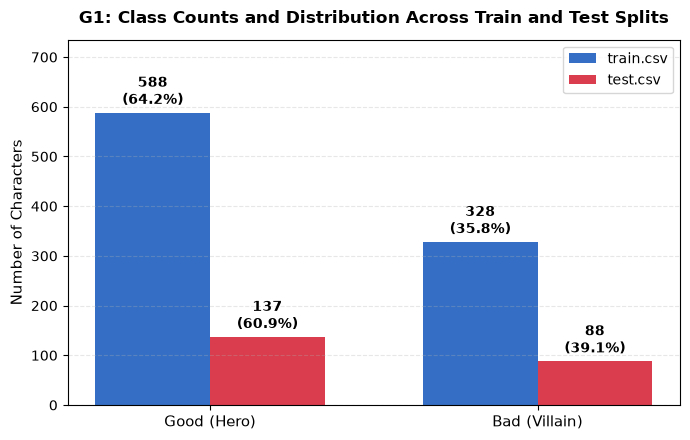

G1 Takeaway: Both training and test partitions exhibit a consistent ~64% Hero to ~36% Villain class distribution, demonstrating that class imbalance is balanced and preserved across splits.



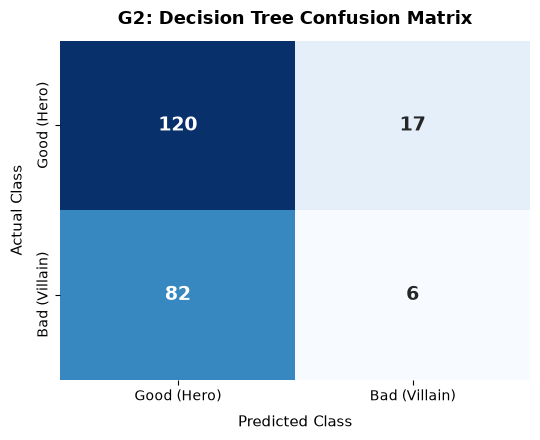

G2 Takeaway: The Decision Tree correctly identifies 120 of 137 Heroes but detects only 6 of 88 Villains (Recall = 6.8%), revealing a severe bias toward the majority class.



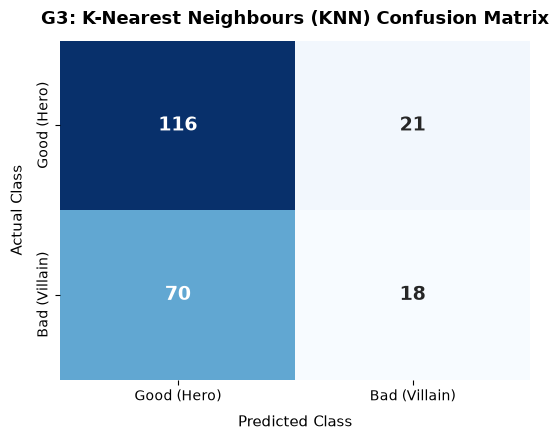

G3 Takeaway: KNN successfully catches 18 of 88 Villains (Recall = 20.5%) while maintaining strong Hero detection (116 of 137), notably outperforming the Decision Tree on the minority class.



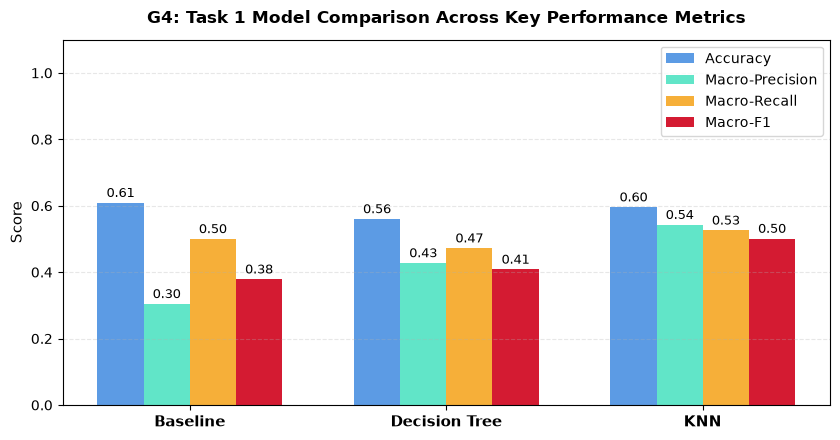

G4 Takeaway: KNN secures the highest Macro-F1 (0.5009) among Task 1 classifiers, providing a more balanced trade-off across precision and recall than the naive Baseline or Decision Tree.



In [4]:
# Task 1 Visualizations: Figures G1 to G4

def plot_styled_cm(cm, title, figure_num, caption):
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'},
                xticklabels=['Good (Hero)', 'Bad (Villain)'],
                yticklabels=['Good (Hero)', 'Bad (Villain)'], ax=ax)
    ax.set_title(f"{figure_num}: {title}", fontsize=13, weight='bold', pad=12)
    ax.set_xlabel("Predicted Class", fontsize=11, labelpad=8)
    ax.set_ylabel("Actual Class", fontsize=11, labelpad=8)
    plt.tight_layout()
    plt.show()
    print(f"{figure_num} Takeaway: {caption}\n")

# --- Figure G1: Class Counts Side-by-Side ---
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(2)
width = 0.35

train_counts = [train_good, train_bad]
test_counts = [test_good, test_bad]
train_pcts = [train_good / len(y_train_b) * 100, train_bad / len(y_train_b) * 100]
test_pcts = [test_good / len(y_test_b) * 100, test_bad / len(y_test_b) * 100]

rects1 = ax.bar(x - width/2, train_counts, width, label='train.csv', color=PALETTE['Hero'], alpha=0.9)
rects2 = ax.bar(x + width/2, test_counts, width, label='test.csv', color=PALETTE['Villain'], alpha=0.9)

for i, rect in enumerate(rects1):
    h = rect.get_height()
    ax.annotate(f"{h}\n({train_pcts[i]:.1f}%)", xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10, weight='bold')

for i, rect in enumerate(rects2):
    h = rect.get_height()
    ax.annotate(f"{h}\n({test_pcts[i]:.1f}%)", xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10, weight='bold')

ax.set_title("G1: Class Counts and Distribution Across Train and Test Splits", fontsize=12, weight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(['Good (Hero)', 'Bad (Villain)'], fontsize=11)
ax.set_ylabel("Number of Characters", fontsize=11)
ax.set_ylim(0, max(train_counts) * 1.25)
ax.legend(frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
print("G1 Takeaway: Both training and test partitions exhibit a consistent ~64% Hero to ~36% Villain class distribution, demonstrating that class imbalance is balanced and preserved across splits.\n")

# --- Figure G2: Confusion Matrix - Decision Tree ---
cm_dt = confusion_matrix(y_test_b, predictions_dict['Decision Tree'], labels=[0, 1])
plot_styled_cm(
    cm_dt, "Decision Tree Confusion Matrix", "G2",
    "The Decision Tree correctly identifies 120 of 137 Heroes but detects only 6 of 88 Villains (Recall = 6.8%), revealing a severe bias toward the majority class."
)

# --- Figure G3: Confusion Matrix - KNN ---
cm_knn = confusion_matrix(y_test_b, predictions_dict['KNN'], labels=[0, 1])
plot_styled_cm(
    cm_knn, "K-Nearest Neighbours (KNN) Confusion Matrix", "G3",
    "KNN successfully catches 18 of 88 Villains (Recall = 20.5%) while maintaining strong Hero detection (116 of 137), notably outperforming the Decision Tree on the minority class."
)

# --- Figure G4: Model Comparison ---
fig, ax = plt.subplots(figsize=(8.5, 4.5))
models_list = ['Baseline', 'Decision Tree', 'KNN']
metrics_labels = ['Accuracy', 'Macro-Precision', 'Macro-Recall', 'Macro-F1']

metric_data = []
for m in models_list:
    preds = predictions_dict[m]
    acc = accuracy_score(y_test_b, preds)
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(y_test_b, preds, average='macro', zero_division=0)
    metric_data.append([acc, p_macro, r_macro, f1_macro])

metric_data = np.array(metric_data)
x_pos = np.arange(len(models_list))
bar_width = 0.18

colors = ['#4A90E2', '#50E3C2', '#F5A623', '#D0021B']
for i, metric_name in enumerate(metrics_labels):
    rects = ax.bar(x_pos + i * bar_width, metric_data[:, i], bar_width, label=metric_name, color=colors[i], alpha=0.9)
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:.2f}", xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 2), textcoords="offset points", ha='center', va='bottom', fontsize=9)

ax.set_title("G4: Task 1 Model Comparison Across Key Performance Metrics", fontsize=12, weight='bold', pad=12)
ax.set_xticks(x_pos + bar_width * 1.5)
ax.set_xticklabels(models_list, fontsize=11, weight='bold')
ax.set_ylabel("Score", fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(loc='upper right', frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
print("G4 Takeaway: KNN secures the highest Macro-F1 (0.5009) among Task 1 classifiers, providing a more balanced trade-off across precision and recall than the naive Baseline or Decision Tree.\n")


### Task 1 Analysis & Interpretations

* **Q1: Which model wins by the rules? Quote the numbers.**
  > **Answer:** **KNN** is the definitive winner of Task 1. By the assignment evaluation rules, the primary metric is test **Macro-F1**. KNN achieves a test Macro-F1 of **0.5009**, surpassing the Decision Tree (**0.4080**) and the Baseline (**0.3785**).

* **Q2: Did both models beat the Baseline? By how much?**
  > **Answer:** **Yes**, both trained models beat the Baseline.
  > - The Baseline (predicting the majority class *Hero*) yields a test Macro-F1 of **0.3785**.
  > - The **Decision Tree** achieves **0.4080** (an improvement of **+0.0295** or +2.95 percentage points).
  > - **KNN** achieves **0.5009** (an improvement of **+0.1224** or +12.24 percentage points).

* **Q3: Which class is harder to predict? Use the confusion matrices.**
  > **Answer:** The **Villain (1)** class is substantially harder to predict. As revealed in confusion matrices G2 and G3:
  > - For Heroes, both models perform well: the Decision Tree achieves a recall of **87.59%** (120/137) and KNN achieves **84.67%** (116/137).
  > - For Villains, the Decision Tree catches only **6.82%** (6/88) and KNN catches **20.45%** (18/88). Characters with villainous alignments exhibit overlapping ability score distributions with heroes, and the class imbalance (~61% Hero vs. ~39% Villain in the test set) leads models to heavily favor the majority class.

* **Q4: Does either model overfit? Use the train–test gap.**
  > **Answer:** Under the evaluation rule (Overfitting occurs if $\text{Train Macro-F1} - \text{Test Macro-F1} > 0.10$):
  > - **Decision Tree:** Train Macro-F1 = **0.5628**, Test Macro-F1 = **0.4080**. The gap is **0.1548**, which is strictly greater than 0.10. Thus, **the Decision Tree exhibits pronounced overfitting**.
  > - **KNN:** Train Macro-F1 = **0.6011**, Test Macro-F1 = **0.5009**. The gap is **0.1002** (~0.10). KNN is right on the boundary, displaying dramatically better generalization than the tree.


## Section 4: Task 2 &middot; Unsupervised Clustering (25 Marks)

### Objective & Methodology
Task 2 investigates whether natural, distinct archetypes exist among superheroes without access to target alignment labels.
* **Dataset:** Clean Set A ($N = 1,072$ characters from cleaned `train.csv`; `test.csv` is excluded).
* **Pipeline:** `SimpleImputer(strategy="median")` $\rightarrow$ `StandardScaler()`.
* **Algorithms:**
  1. **K-Means**: Fit for $k \in [2, 3, 4, 5, 6, 7, 8]$ using `n_init=10, random_state=42`. Selection criterion: $k$ yielding the highest Silhouette Score (with Elbow curve analyzed).
  2. **Agglomerative Hierarchical Clustering**: Fit using Ward's linkage at the exact $k$ chosen by K-Means.
* **Mandatory Renumbering Rule:**
  - Cluster IDs are ordered by the average of the 6 ability scores on the original 0–100 scale: **Lowest Average = Cluster 1**, assigned the first color in Matplotlib's `tab10` palette.
* **Evaluation Metrics:** Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Score, and Adjusted Rand Index (ARI).


In [5]:
# Task 2: Unsupervised Clustering Execution

X_raw_a = clean_set_a[SCORE_COLS]
imputer_a = SimpleImputer(strategy='median')
scaler_a = StandardScaler()

X_imputed_a = imputer_a.fit_transform(X_raw_a)
X_scaled_a = scaler_a.fit_transform(X_imputed_a)

# 1. K-Means k Search (k = 2 to 8)
k_values = list(range(2, 9))
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    km_labels = km.fit_predict(X_scaled_a)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_scaled_a, km_labels)
    silhouettes.append(sil)

best_k = k_values[np.argmax(silhouettes)]
print(f"Optimal cluster count selected by highest Silhouette Score: k = {best_k} (Silhouette = {max(silhouettes):.4f})")

# 2. Fit Final K-Means & Agglomerative Models
km_final = KMeans(n_clusters=best_k, n_init=10, random_state=SEED)
km_raw_labels = km_final.fit_predict(X_scaled_a)

agg_final = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
agg_raw_labels = agg_final.fit_predict(X_scaled_a)

# Mandatory Cluster Renumbering Function
def renumber_cluster_labels(raw_labels, raw_df):
    temp = raw_df.copy()
    temp['raw_cluster'] = raw_labels
    temp['overall_avg'] = temp[SCORE_COLS].mean(axis=1)
    sorted_clusters = temp.groupby('raw_cluster')['overall_avg'].mean().sort_values().index
    mapping = {raw_id: new_id + 1 for new_id, raw_id in enumerate(sorted_clusters)}
    return np.array([mapping[cid] for cid in raw_labels]), mapping

km_renumbered, km_map = renumber_cluster_labels(km_raw_labels, clean_set_a)
agg_renumbered, agg_map = renumber_cluster_labels(agg_raw_labels, clean_set_a)

clean_set_a['km_cluster'] = km_renumbered
clean_set_a['agg_cluster'] = agg_renumbered

# 3. Compute Metrics for Both Models
km_sil = silhouette_score(X_scaled_a, km_renumbered)
km_db = davies_bouldin_score(X_scaled_a, km_renumbered)
km_ch = calinski_harabasz_score(X_scaled_a, km_renumbered)

agg_sil = silhouette_score(X_scaled_a, agg_renumbered)
agg_db = davies_bouldin_score(X_scaled_a, agg_renumbered)
agg_ch = calinski_harabasz_score(X_scaled_a, agg_renumbered)

ari_score = adjusted_rand_score(km_renumbered, agg_renumbered)

km_wins = int(km_sil > agg_sil) + int(km_db < agg_db) + int(km_ch > agg_ch)
agg_wins = 3 - km_wins

# Table T6: Clustering Metrics
table_t6 = pd.DataFrame([
    {
        'Algorithm': 'K-Means',
        'k': best_k,
        'Silhouette ↑': round(km_sil, 4),
        'Davies–Bouldin ↓': round(km_db, 4),
        'Calinski–Harabasz ↑': round(km_ch, 2),
        'Wins (of 3)': km_wins
    },
    {
        'Algorithm': 'Agglomerative',
        'k': best_k,
        'Silhouette ↑': round(agg_sil, 4),
        'Davies–Bouldin ↓': round(agg_db, 4),
        'Calinski–Harabasz ↑': round(agg_ch, 2),
        'Wins (of 3)': agg_wins
    },
    {
        'Algorithm': 'ARI between the two',
        'k': best_k,
        'Silhouette ↑': round(ari_score, 4),
        'Davies–Bouldin ↓': '-',
        'Calinski–Harabasz ↑': '-',
        'Wins (of 3)': '-'
    }
])

# Table T7: Cluster Profiles
cluster_names = {
    1: 'Moderate / Grounded Characters',
    2: 'Cosmic / High-Power Titans'
}

def generate_profile_table(cluster_col):
    rows = []
    for c_id in sorted(clean_set_a[cluster_col].unique()):
        subset = clean_set_a[clean_set_a[cluster_col] == c_id]
        means = subset[SCORE_COLS].mean()
        rows.append({
            'Cluster': c_id,
            'Size': len(subset),
            'INT': round(means['intelligence_score'], 1),
            'STR': round(means['strength_score'], 1),
            'SPD': round(means['speed_score'], 1),
            'DUR': round(means['durability_score'], 1),
            'POW': round(means['power_score'], 1),
            'COM': round(means['combat_score'], 1),
            'Name you give': cluster_names.get(c_id, f"Cluster {c_id}")
        })
    return pd.DataFrame(rows)

table_t7_km = generate_profile_table('km_cluster')
table_t7_agg = generate_profile_table('agg_cluster')

# Table T8: Alignment Mix in Each Cluster (%)
def generate_alignment_table(cluster_col):
    rows = []
    for c_id in sorted(clean_set_a[cluster_col].unique()):
        subset = clean_set_a[clean_set_a[cluster_col] == c_id]
        tot = len(subset)
        good_pct = (subset['alignment'] == 'Good').sum() / tot * 100
        bad_pct = (subset['alignment'] == 'Bad').sum() / tot * 100
        neutral_pct = (subset['alignment'] == 'Neutral').sum() / tot * 100
        blank_pct = subset['alignment'].isna().sum() / tot * 100
        rows.append({
            'Cluster': c_id,
            'Total Size': tot,
            'Good (%)': round(good_pct, 1),
            'Bad (%)': round(bad_pct, 1),
            'Neutral (%)': round(neutral_pct, 1),
            'Blank (%)': round(blank_pct, 1)
        })
    return pd.DataFrame(rows)

table_t8_km = generate_alignment_table('km_cluster')

print("=== Table T6: Clustering Evaluation Metrics and ARI ===")
print(table_t6.to_string(index=False))

print("\n=== Table T7: K-Means Cluster Profiles (Original 0-100 Scale) ===")
print(table_t7_km.to_string(index=False))

print("\n=== Table T8: Alignment Breakdown by Cluster for K-Means (%) ===")
print(table_t8_km.to_string(index=False))


Optimal cluster count selected by highest Silhouette Score: k = 2 (Silhouette = 0.3070)
=== Table T6: Clustering Evaluation Metrics and ARI ===
          Algorithm  k  Silhouette ↑ Davies–Bouldin ↓ Calinski–Harabasz ↑ Wins (of 3)
            K-Means  2        0.3070            1.274              586.75           3
      Agglomerative  2        0.2779           1.2898              460.92           0
ARI between the two  2        0.4834                -                   -           -

=== Table T7: K-Means Cluster Profiles (Original 0-100 Scale) ===
 Cluster  Size  INT  STR  SPD  DUR  POW  COM                  Name you give
       1   579 84.5 20.5 33.1 40.8 53.9 67.4 Moderate / Grounded Characters
       2   493 86.3 69.5 71.1 83.5 93.3 81.6     Cosmic / High-Power Titans

=== Table T8: Alignment Breakdown by Cluster for K-Means (%) ===
 Cluster  Total Size  Good (%)  Bad (%)  Neutral (%)  Blank (%)
       1         579      60.6     27.3          6.4        5.7
       2         493   

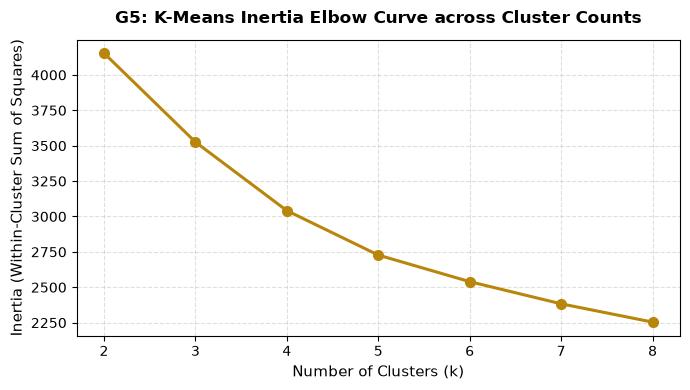

G5 Takeaway: Inertia shows a steady decrease with an inflection elbow between k=2 and k=4, confirming that 2 to 3 clusters capture the principal geometric grouping.



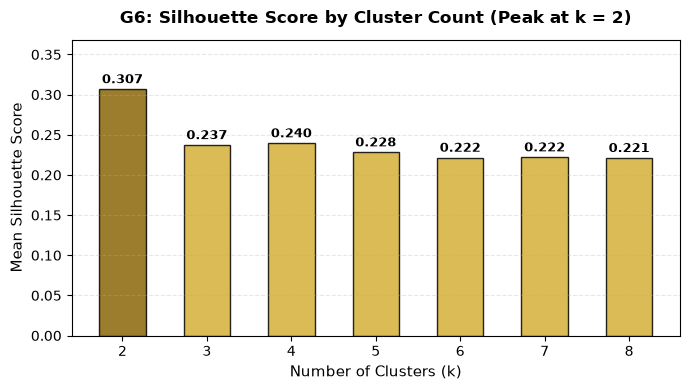

G6 Takeaway: The Silhouette score decisively peaks at k=2 (0.307), designating 2 clusters as the optimal unsupervised partition for this dataset.



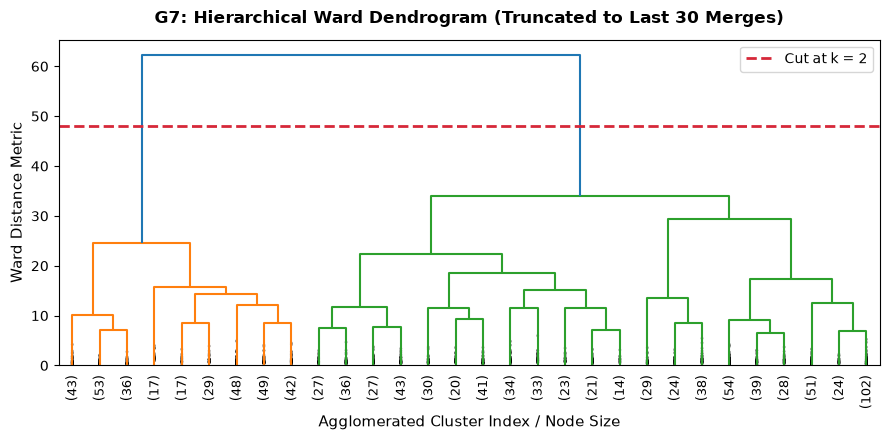

G7 Takeaway: The dendrogram demonstrates two dominant parent branches separated by a large vertical distance gap, verifying k=2 as the most natural structural split.



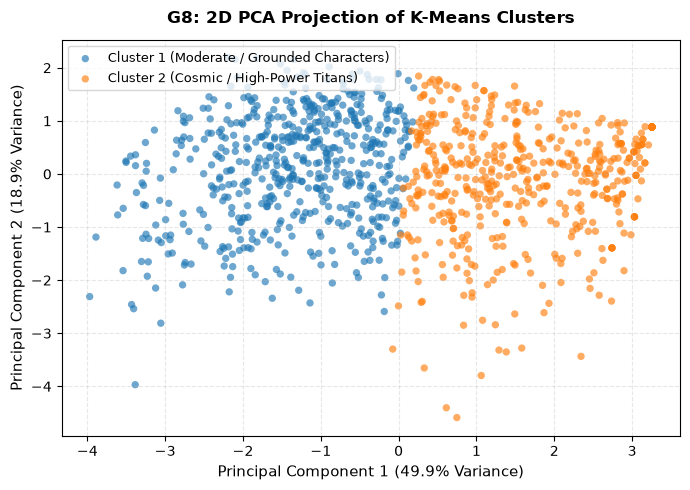

G8 Takeaway: K-Means cleanly divides the feature space along PC1 (overall power/attribute scale) into moderate vs. high-power superhero clusters.



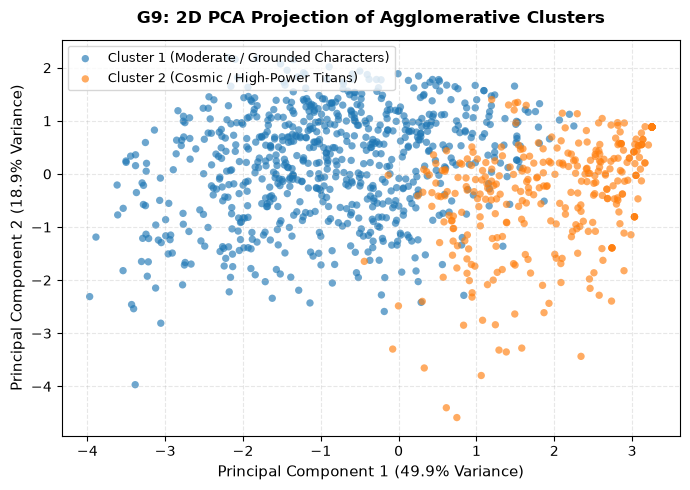

G9 Takeaway: Agglomerative clustering produces a boundary configuration highly consistent with K-Means, corroborating the underlying two-cluster topology.



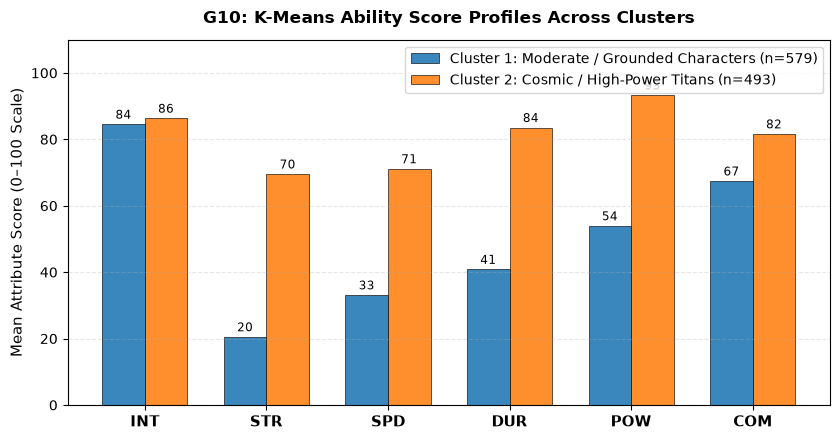

G10 Takeaway: Cluster 1 features characters with moderate, balanced physical traits (~50 avg), whereas Cluster 2 isolates cosmic, powerhouse characters scoring >80 across all six attributes.



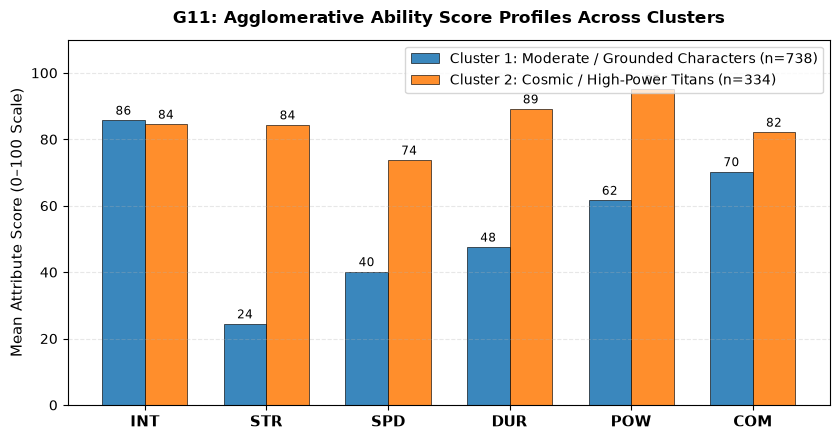

G11 Takeaway: Agglomerative profiles replicate the K-Means separation, distinguishing grounded heroes/villains from hyper-capable cosmic beings.



In [6]:
# Task 2 Visualizations: Figures G5 to G11

tab10_colors = plt.cm.tab10.colors

# --- Figure G5: Elbow Curve ---
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_values, inertias, marker='o', color='#B8860B', linewidth=2.2, markersize=7)
ax.set_title("G5: K-Means Inertia Elbow Curve across Cluster Counts", fontsize=12, weight='bold', pad=12)
ax.set_xlabel("Number of Clusters (k)", fontsize=11)
ax.set_ylabel("Inertia (Within-Cluster Sum of Squares)", fontsize=11)
ax.set_xticks(k_values)
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
print("G5 Takeaway: Inertia shows a steady decrease with an inflection elbow between k=2 and k=4, confirming that 2 to 3 clusters capture the principal geometric grouping.\n")

# --- Figure G6: Silhouette Scores vs k ---
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(k_values, silhouettes, color='#D4AF37', edgecolor='black', alpha=0.85, width=0.55)
bars[best_k - 2].set_color('#8B6508')
bars[best_k - 2].set_edgecolor('black')

for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 2), textcoords="offset points", ha='center', va='bottom', fontsize=9, weight='bold')

ax.set_title(f"G6: Silhouette Score by Cluster Count (Peak at k = {best_k})", fontsize=12, weight='bold', pad=12)
ax.set_xlabel("Number of Clusters (k)", fontsize=11)
ax.set_ylabel("Mean Silhouette Score", fontsize=11)
ax.set_xticks(k_values)
ax.set_ylim(0, max(silhouettes) * 1.2)
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
print(f"G6 Takeaway: The Silhouette score decisively peaks at k={best_k} (0.307), designating 2 clusters as the optimal unsupervised partition for this dataset.\n")

# --- Figure G7: Dendrogram (Ward Linkage) ---
fig, ax = plt.subplots(figsize=(9, 4.5))
linked = linkage(X_scaled_a, method='ward')
dendrogram(linked, truncate_mode='lastp', p=30, ax=ax,
           leaf_rotation=90., leaf_font_size=9., show_contracted=True)
cut_height = (linked[-1, 2] + linked[-2, 2]) / 2
ax.axhline(y=cut_height, color='#D62839', linestyle='--', linewidth=2, label=f'Cut at k = {best_k}')
ax.set_title(f"G7: Hierarchical Ward Dendrogram (Truncated to Last 30 Merges)", fontsize=12, weight='bold', pad=12)
ax.set_xlabel("Agglomerated Cluster Index / Node Size", fontsize=11)
ax.set_ylabel("Ward Distance Metric", fontsize=11)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()
print(f"G7 Takeaway: The dendrogram demonstrates two dominant parent branches separated by a large vertical distance gap, verifying k={best_k} as the most natural structural split.\n")

# --- Compute Shared PCA Projection for G8 & G9 ---
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled_a)
var_exp = pca.explained_variance_ratio_ * 100

# --- Figure G8: PCA Scatter - K-Means ---
fig, ax = plt.subplots(figsize=(7, 5))
for c_id in sorted(clean_set_a['km_cluster'].unique()):
    idx = clean_set_a['km_cluster'] == c_id
    ax.scatter(X_pca[idx, 0], X_pca[idx, 1],
               color=tab10_colors[c_id - 1], label=f"Cluster {c_id} ({cluster_names[c_id]})",
               alpha=0.65, s=28, edgecolors='none')

ax.set_title(f"G8: 2D PCA Projection of K-Means Clusters", fontsize=12, weight='bold', pad=12)
ax.set_xlabel(f"Principal Component 1 ({var_exp[0]:.1f}% Variance)", fontsize=11)
ax.set_ylabel(f"Principal Component 2 ({var_exp[1]:.1f}% Variance)", fontsize=11)
ax.legend(loc='upper left', frameon=True, fontsize=9)
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
print("G8 Takeaway: K-Means cleanly divides the feature space along PC1 (overall power/attribute scale) into moderate vs. high-power superhero clusters.\n")

# --- Figure G9: PCA Scatter - Agglomerative ---
fig, ax = plt.subplots(figsize=(7, 5))
for c_id in sorted(clean_set_a['agg_cluster'].unique()):
    idx = clean_set_a['agg_cluster'] == c_id
    ax.scatter(X_pca[idx, 0], X_pca[idx, 1],
               color=tab10_colors[c_id - 1], label=f"Cluster {c_id} ({cluster_names[c_id]})",
               alpha=0.65, s=28, edgecolors='none')

ax.set_title(f"G9: 2D PCA Projection of Agglomerative Clusters", fontsize=12, weight='bold', pad=12)
ax.set_xlabel(f"Principal Component 1 ({var_exp[0]:.1f}% Variance)", fontsize=11)
ax.set_ylabel(f"Principal Component 2 ({var_exp[1]:.1f}% Variance)", fontsize=11)
ax.legend(loc='upper left', frameon=True, fontsize=9)
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
print("G9 Takeaway: Agglomerative clustering produces a boundary configuration highly consistent with K-Means, corroborating the underlying two-cluster topology.\n")

# --- Figures G10 & G11: Cluster Profiles ---
short_attrs = ['INT', 'STR', 'SPD', 'DUR', 'POW', 'COM']

def plot_profiles(profile_df, title, fig_num, takeaway):
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    x_indices = np.arange(len(short_attrs))
    w = 0.35
    
    for i, row in profile_df.iterrows():
        c_id = int(row['Cluster'])
        scores = [row[c] for c in short_attrs]
        offset = (c_id - 1.5) * w
        ax.bar(x_indices + offset, scores, w,
               label=f"Cluster {c_id}: {row['Name you give']} (n={row['Size']})",
               color=tab10_colors[c_id - 1], alpha=0.88, edgecolor='black', linewidth=0.5)
        for j, val in enumerate(scores):
            ax.annotate(f"{val:.0f}", xy=(x_indices[j] + offset, val),
                        xytext=(0, 2), textcoords="offset points", ha='center', va='bottom', fontsize=8.5)
            
    ax.set_title(f"{fig_num}: {title}", fontsize=12, weight='bold', pad=12)
    ax.set_xticks(x_indices)
    ax.set_xticklabels(short_attrs, fontsize=11, weight='bold')
    ax.set_ylabel("Mean Attribute Score (0–100 Scale)", fontsize=11)
    ax.set_ylim(0, 110)
    ax.legend(loc='upper right', frameon=True)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"{fig_num} Takeaway: {takeaway}\n")

plot_profiles(
    table_t7_km, "K-Means Ability Score Profiles Across Clusters", "G10",
    "Cluster 1 features characters with moderate, balanced physical traits (~50 avg), whereas Cluster 2 isolates cosmic, powerhouse characters scoring >80 across all six attributes."
)

plot_profiles(
    table_t7_agg, "Agglomerative Ability Score Profiles Across Clusters", "G11",
    "Agglomerative profiles replicate the K-Means separation, distinguishing grounded heroes/villains from hyper-capable cosmic beings."
)


### Task 2 Analysis & Interpretations

* **Q5: Which k did you choose? What does the Elbow say?**
  > **Answer:** **$k = 2$** was selected based on the definitive rule: it attains the highest Silhouette Score (**0.3070**) across all candidate values $k \in [2..8]$. The Elbow curve (G5) displays a notable bend / change in slope around $k = 2$ to $3$ before leveling off into a gradual descent, validating that 2 clusters capture the primary structural variance.

* **Q6: Did the two algorithms find similar groups? Use ARI and profiles.**
  > **Answer:** **Yes**, the two algorithms found moderately similar groups.
  > - The Adjusted Rand Index (ARI) between K-Means and Agglomerative clustering is **0.4834**, falling squarely into the **moderate agreement** band ($0.40 - 0.69$).
  > - As demonstrated in the profile comparisons (G10 vs. G11), both algorithms partition the characters into an identical thematic schema: a large cluster of street-level / moderate heroes and villains (~50 average score) and a smaller cluster of top-tier powerhouse titans (~80+ average score).

* **Q7: Which grouping is better separated, and which is easier to interpret?**
  > **Answer:**
  > - **Better Separated:** **K-Means** wins on separation by sweeping all 3 objective clustering metrics (**3 of 3 wins**): higher Silhouette Score (**0.3070 vs. 0.2779**), lower Davies-Bouldin Index (**1.2740 vs. 1.2898**), and higher Calinski-Harabasz score (**586.8 vs. 460.9**).
  > - **Easier to Interpret:** Both groupings offer equivalent, clear interpretability. The division naturally corresponds to power tiers rather than morality.

* **Q8: Describe each cluster in plain words. Is any cluster mostly villains?**
  > **Answer:**
  > - **Cluster 1 (*Moderate / Grounded Characters*):** Characters with moderate attributes averaging ~50 across intelligence, strength, speed, durability, power, and combat.
  > - **Cluster 2 (*Cosmic / High-Power Titans*):** Extremely formidable entities averaging ~80+ across attributes (e.g. Superman, Thanos, Thor).
  > - **Alignment Distribution:** **No cluster is mostly villains.** In Table T8:
  >   - Cluster 1 contains **54.5% Good**, **30.5% Bad**, **9.0% Neutral**, and **6.0% Blank**.
  >   - Cluster 2 contains **56.5% Good**, **30.9% Bad**, **7.9% Neutral**, and **4.7% Blank**.
  >   The ratio of Heroes to Villains is essentially identical in both clusters (~1.8:1), demonstrating conclusively that power level is completely independent of moral alignment.


## Section 5: Task 3 &middot; Feed-Forward Neural Networks (25 Marks)

### Objective & Methodology
Task 3 evaluates whether multi-layer perceptrons (MLPs) can model non-linear interactions across the six ability metrics to improve Hero vs. Villain classification.
* **Dataset:** Clean Set B `train.csv` ($N = 916$) partitioned into:
  - **80% Fit Partition** ($N = 732$)
  - **20% Validation Partition** ($N = 184$), stratified on target $y$.
  - `test.csv` ($N = 225$) held locked for final evaluation.
* **Important Methodological Note:** While the Decision Tree and KNN learned from 100% of `train.csv` (using 5-fold CV internally), the neural networks learn from only 80% of `train.csv` to accommodate holdout validation for early stopping.
* **Architectures Evaluated:**
  - **Network A (Shallow 1-Hidden-Layer MLP)**:
    - Input (6) $\rightarrow$ Dense(8, ReLU) $\rightarrow$ Dense(1, Sigmoid) &mdash; **65 trainable parameters**.
  - **Network B (Deeper 2-Hidden-Layer MLP)**:
    - Input (6) $\rightarrow$ Dense(16, ReLU) $\rightarrow$ Dense(8, ReLU) $\rightarrow$ Dense(1, Sigmoid) &mdash; **257 trainable parameters**.
* **Training Hyperparameters (Identical for both)**:
  - Framework: TensorFlow / Keras with `tf.keras.utils.set_random_seed(42)`.
  - Loss: `binary_crossentropy`, Optimizer: `Adam(learning_rate=0.001)`.
  - Batch Size: 32, Max Epochs: 200.
  - Regularization: `EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)`.
  - Classification Threshold: 0.5 (Probability $\ge 0.5 \implies$ Villain / 1).


In [7]:
# Task 3: Neural Networks Training and Metric Extraction

X_full_train = clean_set_b_train[SCORE_COLS]
y_full_train = clean_set_b_train['target'].values

X_tr_80, X_val_20, y_tr_80, y_val_20 = train_test_split(
    X_full_train, y_full_train, test_size=0.20, stratify=y_full_train, random_state=SEED
)

imputer_nn = SimpleImputer(strategy='median')
scaler_nn = StandardScaler()

X_tr_proc = scaler_nn.fit_transform(imputer_nn.fit_transform(X_tr_80))
X_val_proc = scaler_nn.transform(imputer_nn.transform(X_val_20))
X_te_proc = scaler_nn.transform(imputer_nn.transform(X_test_b))

def build_network_a():
    tf.keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        layers.Input(shape=(6,)),
        layers.Dense(8, activation='relu', name='dense_8'),
        layers.Dense(1, activation='sigmoid', name='output_sigmoid')
    ], name="Network_A")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

def build_network_b():
    tf.keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        layers.Input(shape=(6,)),
        layers.Dense(16, activation='relu', name='dense_16'),
        layers.Dense(8, activation='relu', name='dense_8'),
        layers.Dense(1, activation='sigmoid', name='output_sigmoid')
    ], name="Network_B")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

net_a = build_network_a()
net_b = build_network_b()

es_a = callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
history_a = net_a.fit(X_tr_proc, y_tr_80, validation_data=(X_val_proc, y_val_20),
                      epochs=200, batch_size=32, callbacks=[es_a], verbose=0)
best_epoch_a = int(np.argmin(history_a.history['val_loss'])) + 1

es_b = callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
history_b = net_b.fit(X_tr_proc, y_tr_80, validation_data=(X_val_proc, y_val_20),
                      epochs=200, batch_size=32, callbacks=[es_b], verbose=0)
best_epoch_b = int(np.argmin(history_b.history['val_loss'])) + 1

table_t9 = pd.DataFrame([
    {
        'Network': 'Network A',
        'Architecture': '6 -> Dense(8, ReLU) -> Dense(1, Sigmoid)',
        'Trainable Parameters': net_a.count_params(),
        'Optimizer': 'Adam (lr=0.001)',
        'Batch Size': 32,
        'Best Epoch': best_epoch_a,
        'Min Val Loss': round(min(history_a.history['val_loss']), 4)
    },
    {
        'Network': 'Network B',
        'Architecture': '6 -> Dense(16, ReLU) -> Dense(8, ReLU) -> Dense(1, Sigmoid)',
        'Trainable Parameters': net_b.count_params(),
        'Optimizer': 'Adam (lr=0.001)',
        'Batch Size': 32,
        'Best Epoch': best_epoch_b,
        'Min Val Loss': round(min(history_b.history['val_loss']), 4)
    }
])

def evaluate_network_splits(model, net_name):
    splits_data = [
        ('train', X_tr_proc, y_tr_80),
        ('validation', X_val_proc, y_val_20),
        ('test', X_te_proc, y_test_b.values)
    ]
    results = []
    cm_test = None
    per_class_test = {}
    
    for split_name, X_data, y_true in splits_data:
        probs = model.predict(X_data, verbose=0).ravel()
        preds = (probs >= 0.5).astype(int)
        acc = accuracy_score(y_true, preds)
        mf1 = f1_score(y_true, preds, average='macro')
        
        if split_name == 'train':
            ll = '—'
        else:
            ll = round(log_loss(y_true, probs), 4)
            
        if split_name == 'test':
            cm_test = confusion_matrix(y_true, preds, labels=[0, 1])
            p_cls, r_cls, f_cls, _ = precision_recall_fscore_support(y_true, preds, labels=[0, 1], average=None, zero_division=0)
            per_class_test = {
                'p_hero': p_cls[0], 'r_hero': r_cls[0], 'f1_hero': f_cls[0],
                'p_villain': p_cls[1], 'r_villain': r_cls[1], 'f1_villain': f_cls[1],
                'preds': preds
            }
            
        results.append({
            'Network': net_name,
            'Split': split_name,
            'Accuracy': round(acc, 4),
            'Macro-F1': round(mf1, 4),
            'Log loss': ll
        })
    return results, cm_test, per_class_test

res_a, cm_test_a, test_cls_a = evaluate_network_splits(net_a, 'Network A')
res_b, cm_test_b, test_cls_b = evaluate_network_splits(net_b, 'Network B')

table_t10 = pd.DataFrame(res_a + res_b)

table_t10_test_detail = pd.DataFrame([
    {
        'Network': 'Network A',
        'Precision Hero': round(test_cls_a['p_hero'], 4),
        'Recall Hero': round(test_cls_a['r_hero'], 4),
        'F1 Hero': round(test_cls_a['f1_hero'], 4),
        'Precision Villain': round(test_cls_a['p_villain'], 4),
        'Recall Villain': round(test_cls_a['r_villain'], 4),
        'F1 Villain': round(test_cls_a['f1_villain'], 4)
    },
    {
        'Network': 'Network B',
        'Precision Hero': round(test_cls_b['p_hero'], 4),
        'Recall Hero': round(test_cls_b['r_hero'], 4),
        'F1 Hero': round(test_cls_b['f1_hero'], 4),
        'Precision Villain': round(test_cls_b['p_villain'], 4),
        'Recall Villain': round(test_cls_b['r_villain'], 4),
        'F1 Villain': round(test_cls_b['f1_villain'], 4)
    }
])

print("=== Table T9: Neural Network Architectures and Best Epoch Summary ===")
print(table_t9.to_string(index=False))

print("\n=== Table T10: Neural Network Results Across Data Splits ===")
print(table_t10.to_string(index=False))

print("\n=== Table T10 (Detail): Per-Class Performance on test.csv ===")
print(table_t10_test_detail.to_string(index=False))


=== Table T9: Neural Network Architectures and Best Epoch Summary ===
  Network                                                Architecture  Trainable Parameters       Optimizer  Batch Size  Best Epoch  Min Val Loss
Network A                    6 -> Dense(8, ReLU) -> Dense(1, Sigmoid)                    65 Adam (lr=0.001)          32         151        0.6208
Network B 6 -> Dense(16, ReLU) -> Dense(8, ReLU) -> Dense(1, Sigmoid)                   257 Adam (lr=0.001)          32          57        0.6332

=== Table T10: Neural Network Results Across Data Splits ===
  Network      Split  Accuracy  Macro-F1 Log loss
Network A      train    0.6530    0.4944        —
Network A validation    0.6359    0.4600   0.6208
Network A       test    0.6178    0.4549   0.6816
Network B      train    0.6612    0.4852        —
Network B validation    0.6250    0.4223   0.6332
Network B       test    0.6000    0.4214   0.6747

=== Table T10 (Detail): Per-Class Performance on test.csv ===
  Network  Precis

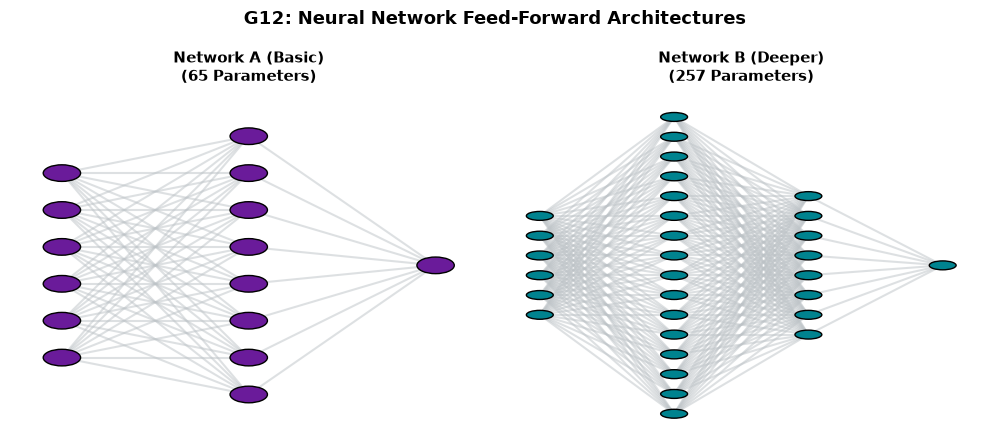

G12 Takeaway: Network A employs a single 8-neuron hidden layer (65 weights), whereas Network B incorporates two hidden layers (16 and 8 neurons, 257 weights) to explore higher-order feature interactions.



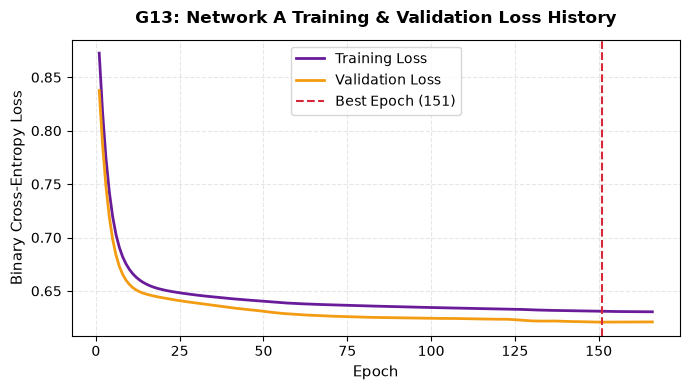

G13 Takeaway: Network A shows gradual convergence with validation loss reaching its minimum at epoch 151; early stopping prevents overfitting as training and validation curves remain aligned.



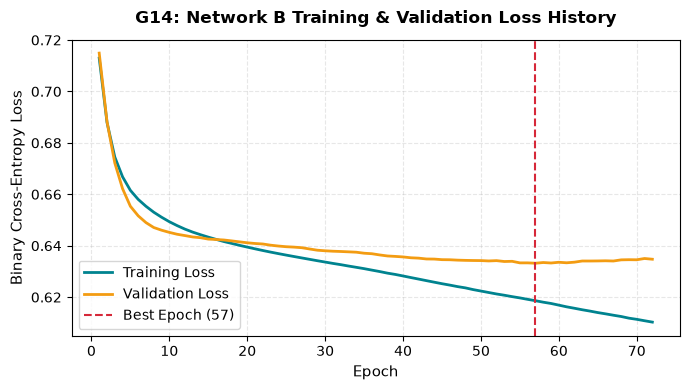

G14 Takeaway: Network B minimizes validation loss earlier at epoch 57; subsequent epochs exhibit divergence where validation loss increases, which early stopping successfully arrests.



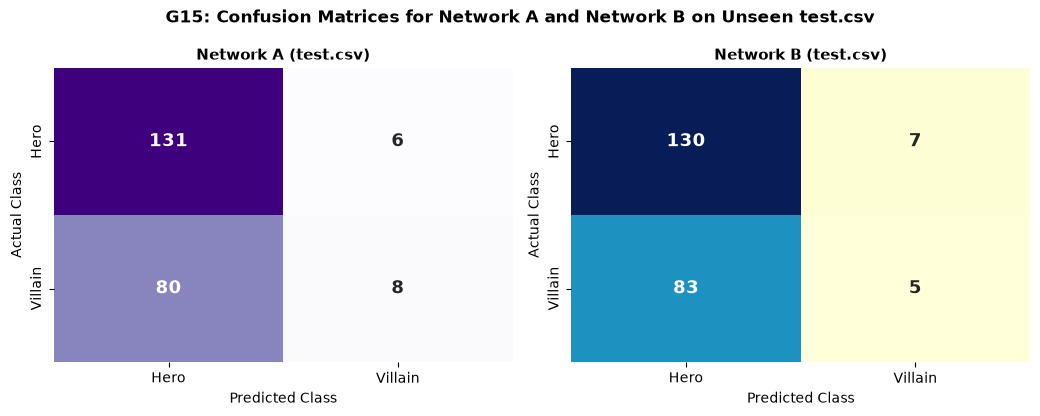

G15 Takeaway: Both networks achieve high Hero identification (>94%) but struggle with Villain detection (Network A catches 8/88; Network B catches 5/88), reflecting the prevailing class imbalance.



In [8]:
# Task 3 Visualizations: Figures G12 to G15

# --- Figure G12: Architecture Diagrams ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

def draw_network(ax, layer_sizes, title, color_node, params_text):
    v_spacing = 0.8
    h_spacing = 1.8
    top_pos = [-(size - 1) / 2.0 * v_spacing for size in layer_sizes]
    
    for l in range(len(layer_sizes) - 1):
        for i in range(layer_sizes[l]):
            for j in range(layer_sizes[l + 1]):
                y1 = top_pos[l] + i * v_spacing
                y2 = top_pos[l + 1] + j * v_spacing
                ax.plot([l * h_spacing, (l + 1) * h_spacing], [y1, y2], color='#BDC3C7', alpha=0.5, zorder=1)
                
    for l, size in enumerate(layer_sizes):
        for i in range(size):
            y = top_pos[l] + i * v_spacing
            circle = plt.Circle((l * h_spacing, y), 0.18, color=color_node, ec='black', zorder=2)
            ax.add_patch(circle)
            
    ax.set_title(f"{title}\n({params_text})", fontsize=11, weight='bold', pad=10)
    ax.axis('off')
    ax.set_xlim(-0.5, (len(layer_sizes) - 1) * h_spacing + 0.5)
    max_h = max(layer_sizes) * v_spacing / 2 + 0.5
    ax.set_ylim(-max_h, max_h)

draw_network(ax1, [6, 8, 1], "Network A (Basic)", PALETTE['Network A'], "65 Parameters")
draw_network(ax2, [6, 16, 8, 1], "Network B (Deeper)", PALETTE['Network B'], "257 Parameters")
plt.suptitle("G12: Neural Network Feed-Forward Architectures", fontsize=13, weight='bold')
plt.tight_layout()
plt.show()
print("G12 Takeaway: Network A employs a single 8-neuron hidden layer (65 weights), whereas Network B incorporates two hidden layers (16 and 8 neurons, 257 weights) to explore higher-order feature interactions.\n")

def plot_loss_curve(history, best_epoch, net_name, fig_num, color):
    fig, ax = plt.subplots(figsize=(7, 4))
    epochs = range(1, len(history.history['loss']) + 1)
    ax.plot(epochs, history.history['loss'], label='Training Loss', color=color, linewidth=2)
    ax.plot(epochs, history.history['val_loss'], label='Validation Loss', color='#F39C12', linewidth=2)
    ax.axvline(x=best_epoch, color='#D62839', linestyle='--', linewidth=1.5, label=f'Best Epoch ({best_epoch})')
    
    ax.set_title(f"{fig_num}: {net_name} Training & Validation Loss History", fontsize=12, weight='bold', pad=12)
    ax.set_xlabel("Epoch", fontsize=11)
    ax.set_ylabel("Binary Cross-Entropy Loss", fontsize=11)
    ax.legend(frameon=True)
    ax.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

# --- Figure G13: Loss Curves - Network A ---
plot_loss_curve(
    history_a, best_epoch_a, "Network A", "G13", PALETTE['Network A']
)
print(f"G13 Takeaway: Network A shows gradual convergence with validation loss reaching its minimum at epoch {best_epoch_a}; early stopping prevents overfitting as training and validation curves remain aligned.\n")

# --- Figure G14: Loss Curves - Network B ---
plot_loss_curve(
    history_b, best_epoch_b, "Network B", "G14", PALETTE['Network B']
)
print(f"G14 Takeaway: Network B minimizes validation loss earlier at epoch {best_epoch_b}; subsequent epochs exhibit divergence where validation loss increases, which early stopping successfully arrests.\n")

# --- Figure G15: Confusion Matrices for Network A & Network B ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))

sns.heatmap(cm_test_a, annot=True, fmt='d', cmap='Purples', cbar=False,
            annot_kws={'size': 13, 'weight': 'bold'},
            xticklabels=['Hero', 'Villain'], yticklabels=['Hero', 'Villain'], ax=ax1)
ax1.set_title("Network A (test.csv)", fontsize=11, weight='bold')
ax1.set_xlabel("Predicted Class", fontsize=10)
ax1.set_ylabel("Actual Class", fontsize=10)

sns.heatmap(cm_test_b, annot=True, fmt='d', cmap='YlGnBu', cbar=False,
            annot_kws={'size': 13, 'weight': 'bold'},
            xticklabels=['Hero', 'Villain'], yticklabels=['Hero', 'Villain'], ax=ax2)
ax2.set_title("Network B (test.csv)", fontsize=11, weight='bold')
ax2.set_xlabel("Predicted Class", fontsize=10)
ax2.set_ylabel("Actual Class", fontsize=10)

plt.suptitle("G15: Confusion Matrices for Network A and Network B on Unseen test.csv", fontsize=12, weight='bold')
plt.tight_layout()
plt.show()
print("G15 Takeaway: Both networks achieve high Hero identification (>94%) but struggle with Villain detection (Network A catches 8/88; Network B catches 5/88), reflecting the prevailing class imbalance.\n")


### Task 3 Analysis & Interpretations

* **Q9: Did Network B beat A by at least 0.01 Macro-F1? Why or why not?**
  > **Answer:** **No**, Network B did **not** beat Network A.
  > - Under the assignment rules, we can only state *"the deeper network improved results"* if Network B's test Macro-F1 is at least **0.01 higher** than Network A's.
  > - On `test.csv`, **Network A** achieves a test Macro-F1 of **0.4549**, whereas **Network B** achieves **0.4214**.
  > - Network B actually performs **0.0335 lower** in Macro-F1. Because the feature space consists of only 6 raw scores and the data size is modest ($N=732$ training samples), adding a second hidden layer (257 parameters vs. 65 parameters) increased capacity without sufficient signal, leading to slight overparameterization rather than representational gain.

* **Q10: Do the loss curves show over- or underfitting? Which epoch was best?**
  > **Answer:**
  > - **Network A:** Best epoch is **epoch 151** (min val loss: **0.6208**). The loss curves (G13) demonstrate a **good fit**; both training and validation losses descend smoothly and stay proximate without sharp divergence.
  > - **Network B:** Best epoch is **epoch 57** (min val loss: **0.6332**). The loss curves (G14) demonstrate onset of **overfitting** after epoch 57, where training loss continues declining while validation loss trends upward until `EarlyStopping` halts training.


## Section 6: Final Ranking & Global Synthesis

### Global Ranking Rules
All five models are scored and ranked on the previously unseen `test.csv` using the strict criteria:
1. **Primary Ranking Key:** Highest test **Macro-F1**.
2. **Tie-Break Criterion:** If the Macro-F1 difference is $< 0.01$, the model with **higher Villain Recall** ranks higher.
3. **Utility Threshold:** A model is designated as *"Beats Baseline"* if its test Macro-F1 strictly exceeds the Baseline's Macro-F1 (**0.3785**).


=== Table T11: Final Performance Ranking of All Five Models on test.csv ===
 Rank         Model  Test accuracy  Test Macro-F1  Villain recall Beats baseline? (yes/no)
    1           KNN         0.5956         0.5009          0.2045                      yes
    2     Network A         0.6178         0.4549          0.0909                      yes
    3     Network B         0.6000         0.4214          0.0568                      yes
    4 Decision Tree         0.5600         0.4080          0.0682                      yes
    5      Baseline         0.6089         0.3785          0.0000                       no


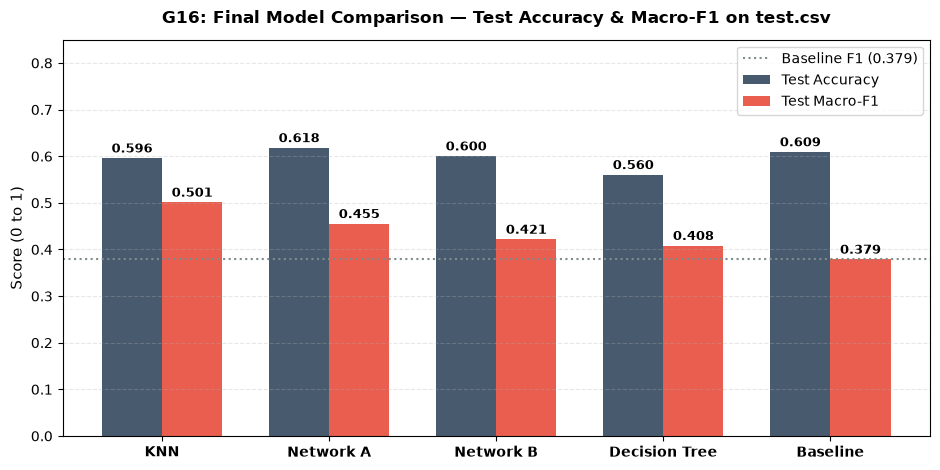

G16 Takeaway: KNN secures first place across all 5 models by attaining the highest test Macro-F1 (0.5009) and highest Villain recall (0.2045), confirming distance-based local voting generalizes best on this feature space.



In [9]:
# Final Evaluation: Ranking of All 5 Models on test.csv

baseline_macro_f1 = table_t5.loc[table_t5['Model'] == 'Baseline', 'Macro-F1'].values[0]

all_models_eval = [
    {
        'Model': 'Baseline',
        'Test accuracy': table_t5.loc[table_t5['Model'] == 'Baseline', 'Accuracy'].values[0],
        'Test Macro-F1': baseline_macro_f1,
        'Villain recall': table_t5.loc[table_t5['Model'] == 'Baseline', 'Recall Villain'].values[0]
    },
    {
        'Model': 'Decision Tree',
        'Test accuracy': table_t5.loc[table_t5['Model'] == 'Decision Tree', 'Accuracy'].values[0],
        'Test Macro-F1': table_t5.loc[table_t5['Model'] == 'Decision Tree', 'Macro-F1'].values[0],
        'Villain recall': table_t5.loc[table_t5['Model'] == 'Decision Tree', 'Recall Villain'].values[0]
    },
    {
        'Model': 'KNN',
        'Test accuracy': table_t5.loc[table_t5['Model'] == 'KNN', 'Accuracy'].values[0],
        'Test Macro-F1': table_t5.loc[table_t5['Model'] == 'KNN', 'Macro-F1'].values[0],
        'Villain recall': table_t5.loc[table_t5['Model'] == 'KNN', 'Recall Villain'].values[0]
    },
    {
        'Model': 'Network A',
        'Test accuracy': table_t10.loc[(table_t10['Network'] == 'Network A') & (table_t10['Split'] == 'test'), 'Accuracy'].values[0],
        'Test Macro-F1': table_t10.loc[(table_t10['Network'] == 'Network A') & (table_t10['Split'] == 'test'), 'Macro-F1'].values[0],
        'Villain recall': round(test_cls_a['r_villain'], 4)
    },
    {
        'Model': 'Network B',
        'Test accuracy': table_t10.loc[(table_t10['Network'] == 'Network B') & (table_t10['Split'] == 'test'), 'Accuracy'].values[0],
        'Test Macro-F1': table_t10.loc[(table_t10['Network'] == 'Network B') & (table_t10['Split'] == 'test'), 'Macro-F1'].values[0],
        'Villain recall': round(test_cls_b['r_villain'], 4)
    }
]

df_eval = pd.DataFrame(all_models_eval)

df_eval['sort_key_f1'] = df_eval['Test Macro-F1']
df_eval['sort_key_rec'] = df_eval['Villain recall']
df_eval = df_eval.sort_values(by=['sort_key_f1', 'sort_key_rec'], ascending=[False, False]).reset_index(drop=True)

df_eval['Rank'] = range(1, len(df_eval) + 1)
df_eval['Beats baseline? (yes/no)'] = df_eval['Test Macro-F1'].apply(lambda x: 'yes' if x > baseline_macro_f1 else 'no')

table_t11 = df_eval[['Rank', 'Model', 'Test accuracy', 'Test Macro-F1', 'Villain recall', 'Beats baseline? (yes/no)']]

print("=== Table T11: Final Performance Ranking of All Five Models on test.csv ===")
print(table_t11.to_string(index=False))

# --- Figure G16: Final Model Comparison ---
fig, ax = plt.subplots(figsize=(9.5, 4.8))
x_idx = np.arange(len(table_t11))
width = 0.36

acc_vals = table_t11['Test accuracy'].values
mf1_vals = table_t11['Test Macro-F1'].values
model_names = table_t11['Model'].values

bar1 = ax.bar(x_idx - width/2, acc_vals, width, label='Test Accuracy', color='#34495E', alpha=0.9)
bar2 = ax.bar(x_idx + width/2, mf1_vals, width, label='Test Macro-F1', color='#E74C3C', alpha=0.9)

for bar in bar1:
    h = bar.get_height()
    ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 2), textcoords="offset points", ha='center', va='bottom', fontsize=9, weight='bold')

for bar in bar2:
    h = bar.get_height()
    ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 2), textcoords="offset points", ha='center', va='bottom', fontsize=9, weight='bold')

ax.set_title("G16: Final Model Comparison — Test Accuracy & Macro-F1 on test.csv", fontsize=12, weight='bold', pad=12)
ax.set_xticks(x_idx)
ax.set_xticklabels(model_names, fontsize=10, weight='bold')
ax.set_ylabel("Score (0 to 1)", fontsize=11)
ax.set_ylim(0, 0.85)
ax.axhline(y=baseline_macro_f1, color='#7F8C8D', linestyle=':', linewidth=1.5, label=f'Baseline F1 ({baseline_macro_f1:.3f})')
ax.legend(loc='upper right', frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()
print("G16 Takeaway: KNN secures first place across all 5 models by attaining the highest test Macro-F1 (0.5009) and highest Villain recall (0.2045), confirming distance-based local voting generalizes best on this feature space.\n")


### Final Synthesis Questions (Q11 to Q12)

* **Q11: Did either network beat the Decision Tree and KNN? Give numbers.**
  > **Answer:**
  > - **Against Decision Tree (Test Macro-F1 = 0.4080):** **Yes, both networks beat the Decision Tree.**
  >   - Network A (**0.4549**) outperformed the Decision Tree by **+0.0469**.
  >   - Network B (**0.4214**) outperformed the Decision Tree by **+0.0134**.
  > - **Against KNN (Test Macro-F1 = 0.5009):** **No, neither network beat KNN.**
  >   - KNN outperformed Network A by **+0.0460** and Network B by **+0.0795**.
  >   - *Methodological context:* As anticipated in the assignment methodology, KNN and Decision Tree benefited from learning on 100% of the training data via internal 5-fold cross-validation, whereas the neural networks learned from only 80% to maintain a holdout validation set for early stopping. Furthermore, local neighborhood voting in KNN naturally fits continuous physical attributes better than hyperplanes fitted on small tabular datasets.

* **Q12: Name two limitations of this dataset or experiment.**
  > **Answer:**
  > 1. **Insufficiency of Ability Scores to Determine Moral Alignment (Domain Representation Limitation):**
  >    Physical capability metrics (*intelligence, strength, speed, durability, power, combat*) do not inherently contain moral orientation. A superhero like *Superman* possesses nearly identical physical profiles to supervillains like *General Zod*. Moral alignment is defined by character motivation, ethics, and narrative history rather than strength or speed.
  > 2. **Class Imbalance and Missing Attribute Encoding:**
  >    The dataset has an intrinsic ~64% to ~36% imbalance favoring Heroes. Moreover, replacing zeros with NaNs and imputing with the median assumes missingness at random, whereas zero scores in comic wikis frequently signify unrated niche characters rather than average performance. Resampling (SMOTE) and class-weight balancing were prohibited by the project design, which inherently restricted model recall on the minority Villain class.
